### Imports

In [1]:
import json
import sys
import matplotlib.pyplot as plt
import pandas as pd
sys.path.append("..")
from src import config
from src.data import *
from src.data import CLASS_NAMES
from src.dataset import *
from src.split import *
from src.train import compare_experiments, load_history, plot_comparison, plot_history

## Dataset Preparation

Download dataset and loadng the split saved in split_seed42.json. 
Then create dataloaders

Creating dataloaders with image size (272, 512), batch size 16, num_workers 4, cache=True, seed=42, augmentation=standard


Computing mean/std:   0%|          | 0/690 [00:00<?, ?it/s]

Caching samples:   0%|          | 0/690 [00:00<?, ?it/s]

Caching samples:   0%|          | 0/186 [00:00<?, ?it/s]

train batches: 43, val batches: 12
mean: (0.42684936680564606, 0.4464529322684391, 0.42237368396772457), std: (0.2610688407790348, 0.259549199474287, 0.2621955384442435)
torch.Size([16, 3, 272, 512]) torch.float32 torch.Size([16, 272, 512]) torch.int64


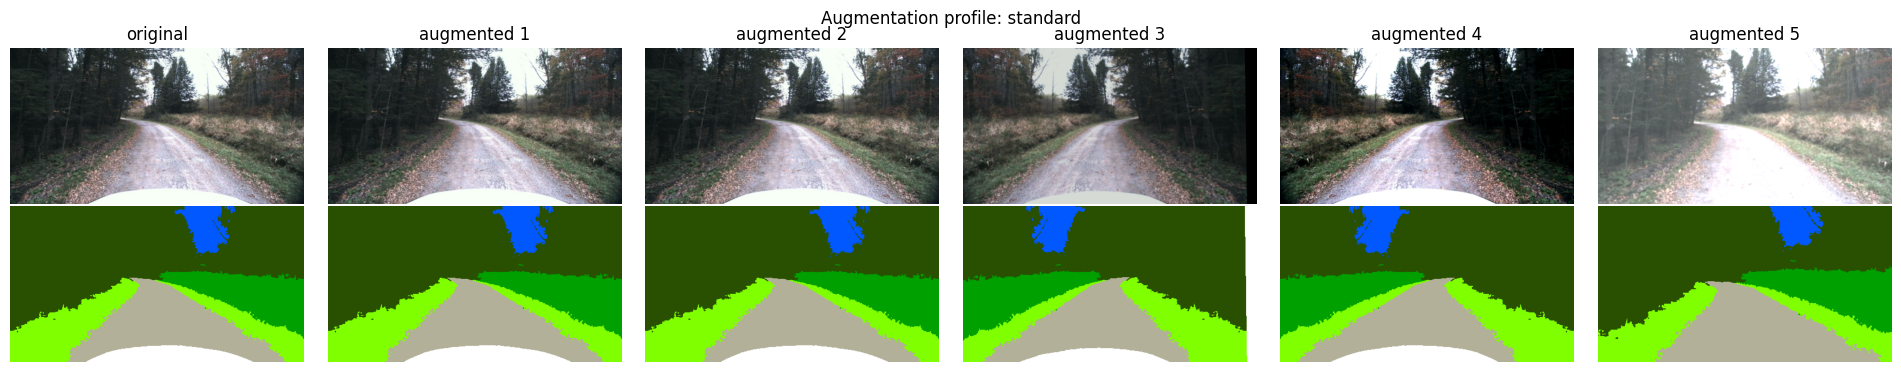

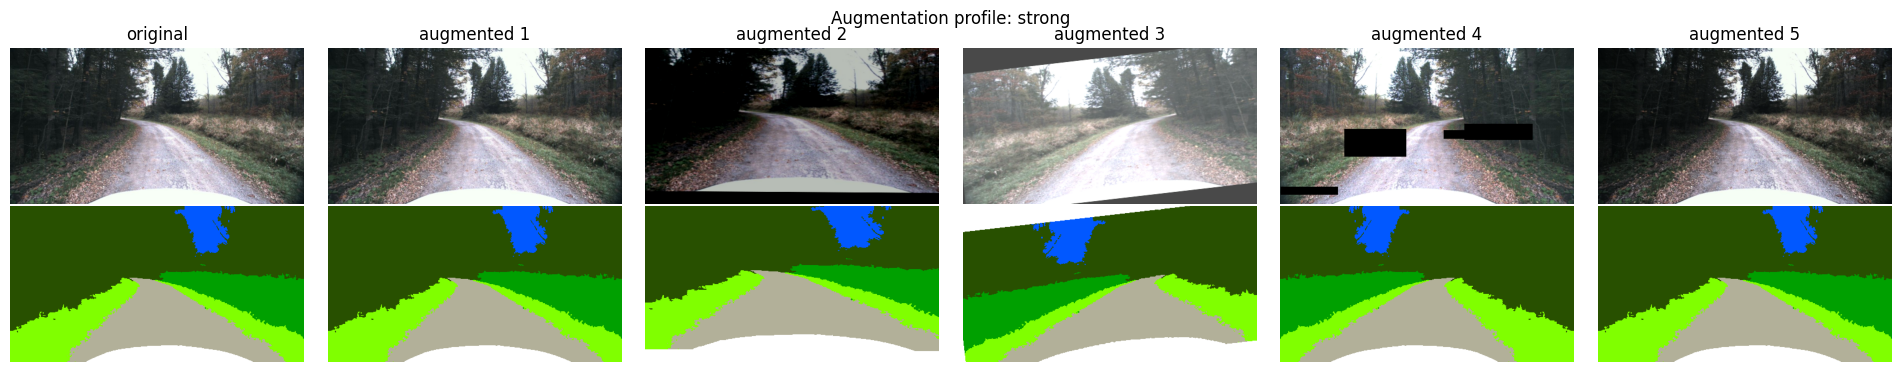

In [2]:
# Find the training samples in ../data/train and return a list of Path objects for each sample
data = download_dataset("../data/train")

# Load the train/val split and create the dataloadersS
train_samples, val_samples = load_split("../data/splits/split_seed42.json", data)

# Create dataloaders for training and validation, computing mean and std 
train_loader, val_loader, mean, std = create_dataloaders( train_samples, val_samples, image_size=config.DEFAULT_IMAGE_SIZE, batch_size=config.BATCH_SIZE, num_workers=config.NUM_WORKERS)
print(f"train batches: {len(train_loader)}, val batches: {len(val_loader)}")
print(f"mean: {mean}, std: {std}")

# Get a batch of images and masks from the training dataloader
images, masks = next(iter(train_loader))
print(images.shape, images.dtype, masks.shape, masks.dtype)

# The augmentation profiles on the same training sample:
# experiments A, B and C use "standard", experiment D uses "strong"
palette = get_palette(data[0])
for profile in config.AUGMENTATIONS:
    fig = plot_augmentations(train_samples[10], mean, std, palette, augmentation=profile)
    fig.suptitle(f"Augmentation profile: {profile}", y=1.02)
    plt.show()

## Running the experiments

The six experiments are defined in `config.EXPERIMENTS` and are run from an Anaconda Prompt
(a run takes from one to a few hours, too long for a notebook cell). Each one writes its results to
`outputs/experiment_<name>/`:

| Experiment | Command | What it is |
|---|---|---|
| A | `python -u -m src.train --experiment A` | U-Net written from scratch |
| B | `python -u -m src.train --experiment B` | ResNet18 encoder pre-trained on ImageNet + U-Net decoder |
| C | `python -u -m src.train --experiment C` | the network of B with random weights |
| D | `python -u -m src.train --experiment D` | B with strong augmentation and a higher weight decay |
| E | `python -u -m src.train --experiment E` | B with a ResNet50 encoder instead of ResNet18 |
| F | `python -u -m src.train --experiment F` | **final network**: the recipe of B trained on all the labelled frames |

To keep the log in a file add `> outputs\log_E.txt 2>&1`. Experiments that have not been run
yet are simply missing from the tables and plots below.

Experiment F is not a comparison: it trains on the training, validation and purged frames, with no
held-out data, so it has no early stopping and no best epoch. Its weights are those of the last
epoch, saved in `outputs/experiment_F/final.pt`, and its score and losses are measured on frames
it was trained on (a sanity check only). It appears in the table with `trained on = train+val`
and is left out of the comparison plot.

## Experiment results

In [3]:
# One row per experiment that has been run: best score and epoch, cost, the settings that differ
# between experiments, training and validation loss at the best epoch, IoU of each class
display(compare_experiments())

,score,best_epoch,epochs,params (M),s/epoch,gpu GB,model,trained on,augmentation,weight decay,...,train loss,val loss,smooth trail,traversable grass,rough trail,puddle,obstacle,non-traversable low vegetation,high vegetation,sky
A,0.3504,10,35,1.9427,28.9346,3.1127,unet,train,standard,0.0001,...,1.6645,1.7434,0.2839,0.2839,0.1787,0.0000,0.0000,0.0370,0.7169,0.6786
B,0.4152,96,110,14.3286,30.6071,3.0401,resnet18_unet,train,standard,0.0001,...,0.2261,2.6087,0.4151,0.2708,0.2032,0.0248,0.0924,0.1165,0.7905,0.7197
C,0.3458,10,35,14.3286,32.3958,3.0401,resnet18_unet,train,standard,0.0001,...,1.6440,1.6608,0.2474,0.3057,0.2269,0.0000,0.0001,0.0462,0.7433,0.6626
D,0.4093,110,110,14.3286,32.3002,3.0401,resnet18_unet,train,strong,0.0500,...,0.4322,2.0710,0.4192,0.2946,0.2072,0.0448,0.0711,0.1115,0.7798,0.7077
E,0.4233,88,110,32.5215,76.7443,4.6012,resnet50_unet,train,standard,0.0001,...,0.2120,2.5981,0.4220,0.2681,0.2279,0.0403,0.1068,0.1268,0.7852,0.7167
F,0.8406,110,110,14.3286,42.7378,3.0401,resnet18_unet,train+val,standard,0.0001,...,0.2040,0.2024,0.8708,0.8083,0.8027,0.8067,0.6411,0.7780,0.9320,0.8386


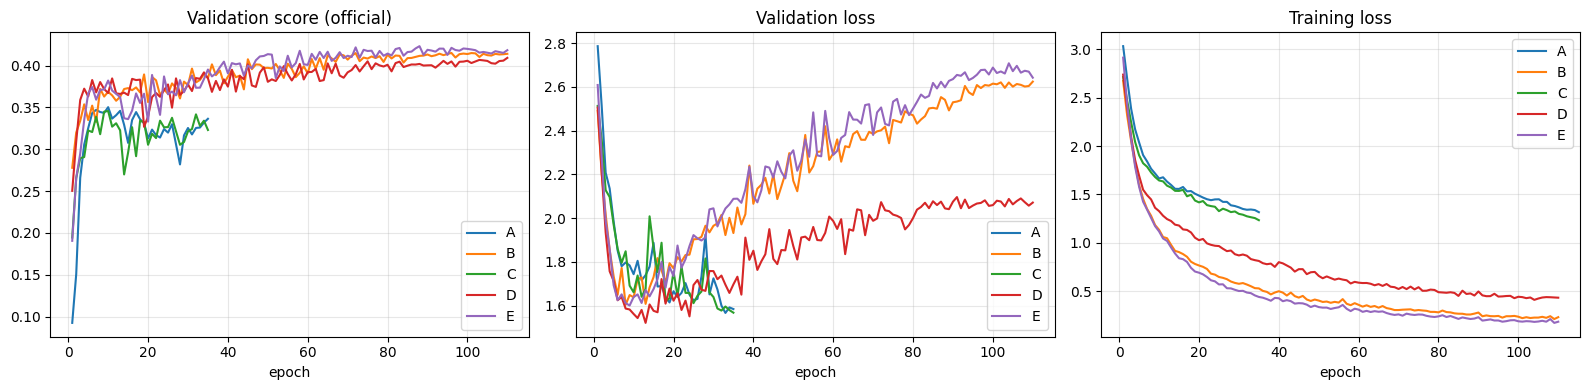

In [4]:
# Validation score, validation loss and training loss of all the experiments on the same axes
plot_comparison()
plt.show()

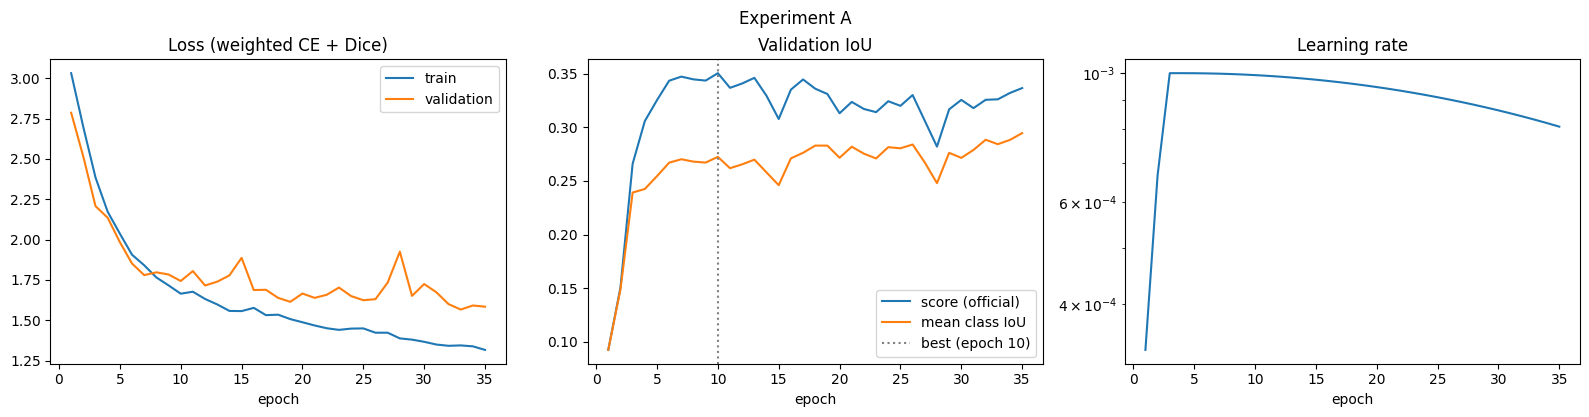

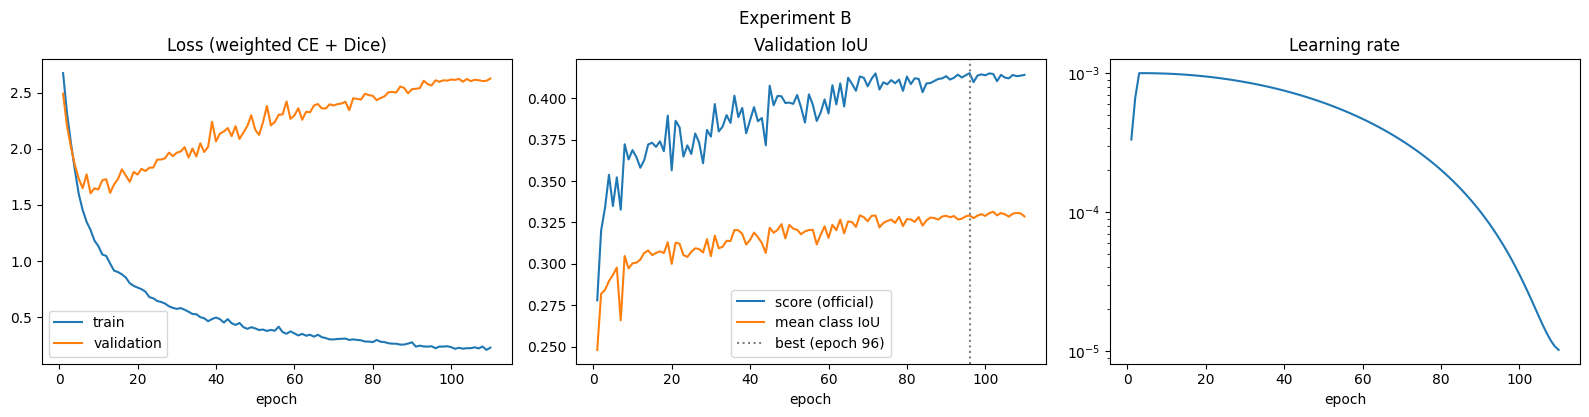

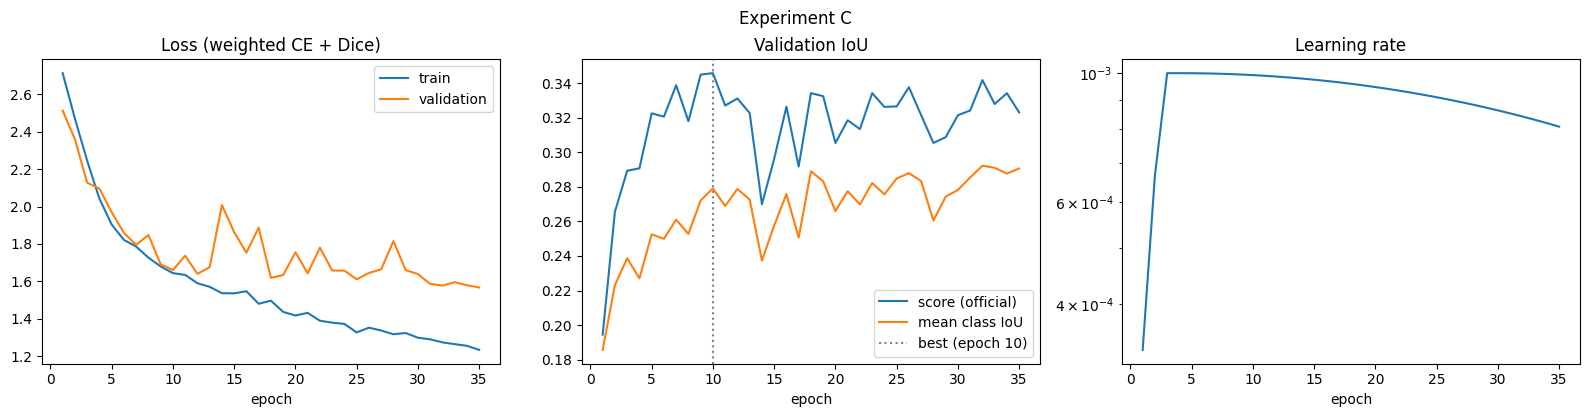

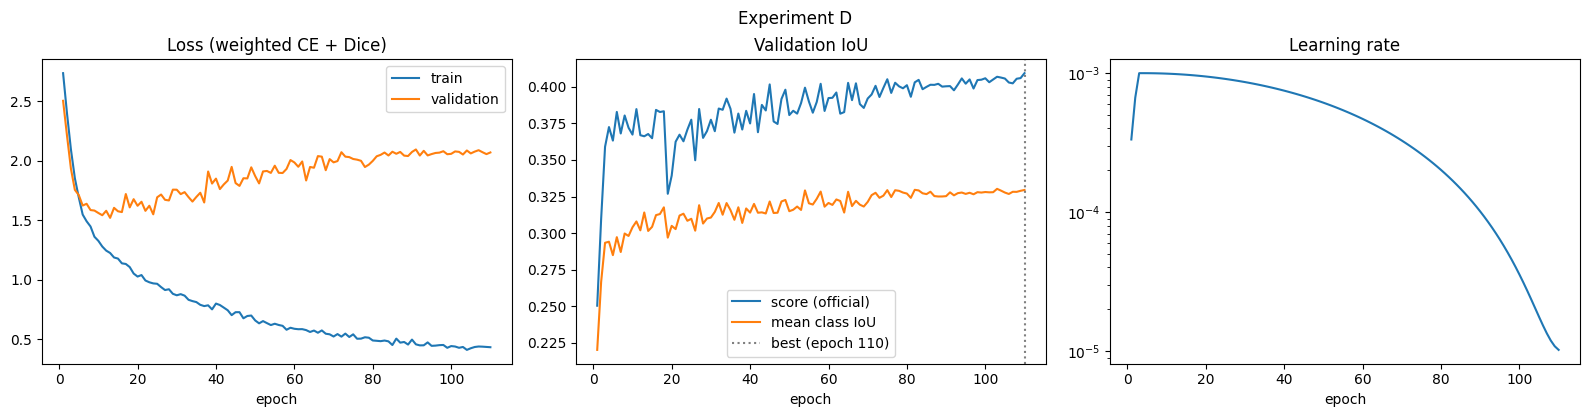

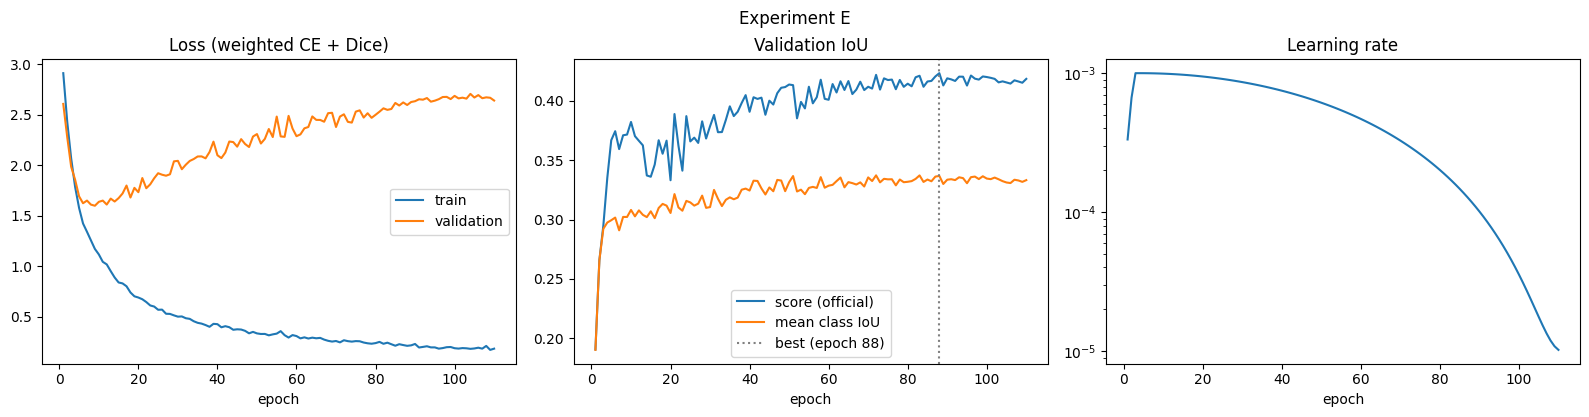

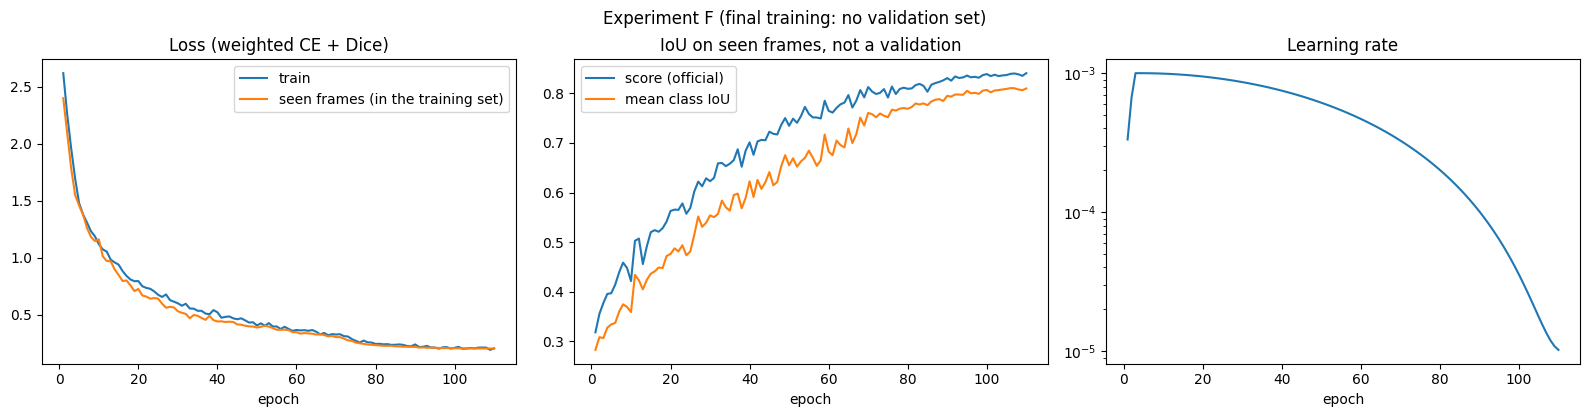

In [5]:
# Detailed curves of every experiment that has been run (losses, validation IoU, learning rate)
results = compare_experiments()
for name in results.index:
    final = results.loc[name, "trained on"] == "train+val"
    fig = plot_history(load_history(name), final_training=final)
    fig.suptitle(f"Experiment {name}" + (" (final training: no validation set)" if final else ""), y=1.03)
    plt.show()

In [6]:
# Effect of each variation of experiment B, class by class (positive = better than B):
# D = stronger regularisation, E = deeper pre-trained encoder (ResNet50)
for name in ("D", "E"):
    pair = compare_experiments(["B", name])
    if {"B", name} <= set(pair.index):
        print(f"Experiment {name} ({pair.loc[name, 'model']}, augmentation {pair.loc[name, 'augmentation']}, "
              f"weight decay {pair.loc[name, 'weight decay']})")
        print(f"  score: B {pair.loc['B', 'score']:.4f}, {name} {pair.loc[name, 'score']:.4f}, "
              f"difference {pair.loc[name, 'score'] - pair.loc['B', 'score']:+.4f} "
              f"(differences below about 0.01 are within the noise of the validation set)")
        print(f"  loss at the best epoch (train / validation): B {pair.loc['B', 'train loss']:.3f} / "
              f"{pair.loc['B', 'val loss']:.3f}, {name} {pair.loc[name, 'train loss']:.3f} / {pair.loc[name, 'val loss']:.3f}")
        print(f"  cost: {pair.loc[name, 'params (M)']:.1f} M parameters, {pair.loc[name, 's/epoch']:.0f} s per epoch, "
              f"{pair.loc[name, 'gpu GB']:.2f} GB of GPU memory (B: {pair.loc['B', 's/epoch']:.0f} s, {pair.loc['B', 'gpu GB']:.2f} GB)")
    else:
        print(f"Run experiments B and {name} first")
classes = CLASS_NAMES[1:]
table = compare_experiments(["B", "D", "E"])
delta = pd.DataFrame({f"{name} - B": table.loc[name, classes].astype(float) - table.loc["B", classes].astype(float)
                      for name in ("D", "E") if {"B", name} <= set(table.index)})
delta.round(3)

Experiment D (resnet18_unet, augmentation strong, weight decay 0.05)
  score: B 0.4152, D 0.4093, difference -0.0059 (differences below about 0.01 are within the noise of the validation set)
  loss at the best epoch (train / validation): B 0.226 / 2.609, D 0.432 / 2.071
  cost: 14.3 M parameters, 32 s per epoch, 3.04 GB of GPU memory (B: 31 s, 3.04 GB)
Experiment E (resnet50_unet, augmentation standard, weight decay 0.0001)
  score: B 0.4152, E 0.4233, difference +0.0081 (differences below about 0.01 are within the noise of the validation set)
  loss at the best epoch (train / validation): B 0.226 / 2.609, E 0.212 / 2.598
  cost: 32.5 M parameters, 77 s per epoch, 4.60 GB of GPU memory (B: 31 s, 3.04 GB)


,D - B,E - B
smooth trail,0.004,0.007
traversable grass,0.024,-0.003
rough trail,0.004,0.025
puddle,0.020,0.016
obstacle,-0.021,0.014
non-traversable low vegetation,-0.005,0.010
high vegetation,-0.011,-0.005
sky,-0.012,-0.003
